# Entrega - Atividade I de Cálculo Numérico
## Erros numéricos em aplicações de biofluidodinâmica

**Nomes dos integrantes:** preencher  
**Turma:** preencher  
**Data:** preencher  
**Divisão das tarefas:** preencher

Este notebook apresenta os cálculos, as tabelas com unidades, os gráficos solicitados, o GIF demonstrativo, o quadro-síntese de resultados, as respostas às questões e a conclusão da atividade.

## Organização da entrega

- **Identificação:** integrantes, turma, data e divisão das tarefas no início.
- **Funções:** truncamento, erros numéricos e vazão de Hagen-Poiseuille na Seção 2.
- **Tabelas e gráficos:** apresentados ao longo das Partes A, B, C e D.
- **Síntese visual:** quadro único em PNG na Parte E.
- **Animação:** GIF com a variação do raio do nanocateter na Seção 8.
- **Respostas:** incluídas ao final de cada parte e na conclusão final.

## Síntese dos resultados

O arredondamento tende a produzir erros menores ou iguais aos do truncamento para a mesma quantidade de casas decimais. Nas medidas de pressão, a representação inteira preserva a média da amostra, mas altera a amplitude, o desvio-padrão e a distribuição. Na relação de Hagen-Poiseuille, a vazão depende de $r^4$, de modo que pequenas incertezas no raio são amplificadas aproximadamente por um fator 4 no erro relativo de $Q$. No nanocateter, precisão aritmética e validade física do modelo são aspectos diferentes.

## 1. Preparação do ambiente

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPythonImage
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "font.size": 10,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# A pasta e os arquivos são relativos ao ambiente atual do Colab.
output_dir = Path("atividade_I_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Ambiente preparado.")

Ambiente preparado.


## 2. Funções auxiliares

In [2]:
def truncar(numero, casas):
    """Trunca um número em `casas` casas decimais, sem arredondar."""
    if casas < 0:
        raise ValueError("A quantidade de casas deve ser não negativa.")

    fator = 10**casas
    return math.trunc(numero * fator) / fator


def calcular_erros(referencia, aproximacao):
    """Retorna erro absoluto, relativo e percentual da aproximação."""
    erro_absoluto = abs(referencia - aproximacao)

    if referencia == 0:
        return erro_absoluto, np.nan, np.nan

    erro_relativo = erro_absoluto / abs(referencia)
    erro_percentual = 100 * erro_relativo
    return erro_absoluto, erro_relativo, erro_percentual


def vazao_hagen_poiseuille(raio_m, comprimento_m, viscosidade_pa_s, delta_p_pa):
    """Calcula Q = pi*r^4*Delta_p/(8*mu*L), em m^3/s."""
    return math.pi * raio_m**4 * delta_p_pa / (
        8 * viscosidade_pa_s * comprimento_m
    )


def mostrar_tabela(tabela, titulo=None):
    """Exibe uma tabela sem índice, com cabeçalho e espaçamento consistentes."""
    estilo = (
        tabela.style
        .hide(axis="index")
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#1f4e79"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                ],
            },
            {
                "selector": "td",
                "props": [("padding", "5px 8px")],
            },
        ])
    )
    if titulo:
        estilo = estilo.set_caption(titulo)
    display(estilo)

print("Funções auxiliares definidas.")

Funções auxiliares definidas.


## 3. Parte A - truncamento e arredondamento

In [3]:
valores_a = {
    "x1": 3.14159265,
    "x2": 98.76543,
    "x3": 0.00498765,
}
casas_decimais = list(range(5))
linhas_a = []

for nome, referencia in valores_a.items():
    for numero_de_casas in casas_decimais:
        aproximacoes = {
            "truncamento": truncar(referencia, numero_de_casas),
            "arredondamento": round(referencia, numero_de_casas),
        }
        for metodo, aproximacao in aproximacoes.items():
            erro_absoluto, erro_relativo, erro_percentual = calcular_erros(
                referencia, aproximacao
            )
            linhas_a.append({
                "valor": nome,
                "referência": referencia,
                "n casas": numero_de_casas,
                "método": metodo,
                "aproximação": aproximacao,
                "$E_a$": erro_absoluto,
                "$E_r$": erro_relativo,
                "$E_{\\%}$": erro_percentual,
            })

tabela_a = pd.DataFrame(linhas_a)
mostrar_tabela(tabela_a, "Parte A - aproximações e erros")

valor,referência,n casas,método,aproximação,$E_a$,$E_r$,$E_{\%}$
x1,3.141593,0,truncamento,3.000000,0.141593,0.045070,4.507034
x1,3.141593,0,arredondamento,3.000000,0.141593,0.045070,4.507034
x1,3.141593,1,truncamento,3.100000,0.041593,0.013239,1.323935
x1,3.141593,1,arredondamento,3.100000,0.041593,0.013239,1.323935
x1,3.141593,2,truncamento,3.140000,0.001593,0.000507,0.050696
x1,3.141593,2,arredondamento,3.140000,0.001593,0.000507,0.050696
x1,3.141593,3,truncamento,3.141000,0.000593,0.000189,0.018865
x1,3.141593,3,arredondamento,3.142000,0.000407,0.000130,0.012966
x1,3.141593,4,truncamento,3.141500,0.000093,0.000029,0.002949
x1,3.141593,4,arredondamento,3.141600,0.000007,0.000002,0.000234


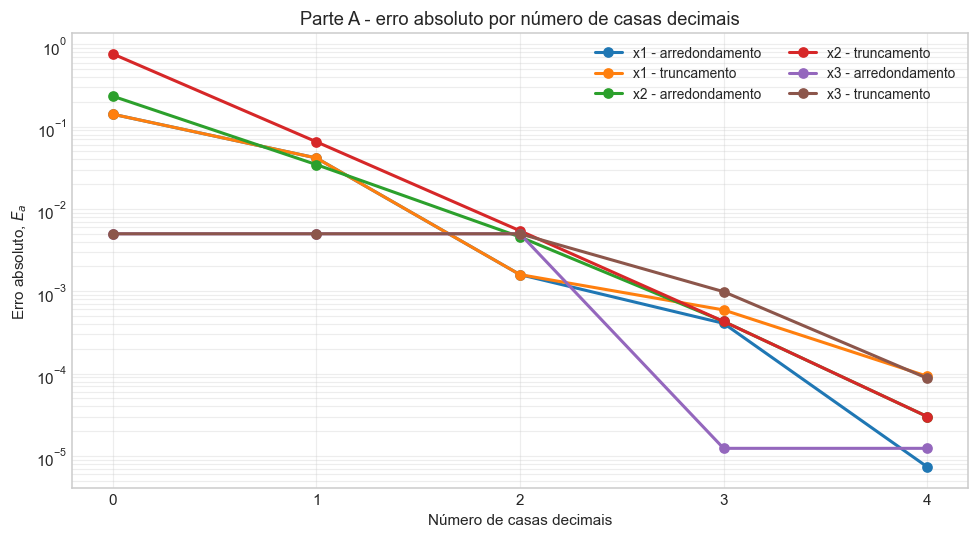

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

for (nome, metodo), dados in tabela_a.groupby(["valor", "método"]):
    ax.plot(
        dados["n casas"],
        dados["$E_a$"],
        marker="o",
        linewidth=2,
        label=f"{nome} - {metodo}",
    )

ax.set_yscale("log")
ax.set_xticks(casas_decimais)
ax.set_title("Parte A - erro absoluto por número de casas decimais")
ax.set_xlabel("Número de casas decimais")
ax.set_ylabel("Erro absoluto, $E_a$")
ax.legend(ncol=2)
ax.grid(True, which="both", alpha=0.35)
plt.tight_layout()
plt.show()

**Resposta - Parte A.** O arredondamento geralmente gera erro menor ou igual ao truncamento porque escolhe o número representável mais próximo na casa decimal desejada, enquanto o truncamento apenas descarta os algarismos posteriores. Nos resultados, isso aparece para $x_1$ e $x_2$ em várias casas decimais. Ainda assim, o arredondamento não elimina o erro: em alguns casos os dois métodos coincidem ou produzem erros muito próximos.

## 4. Parte B - medidas de pressão arterial

In [5]:
pressao_original = np.array([
    121.7, 120.4, 122.1, 119.8, 121.2,
    120.9, 122.4, 121.0, 120.2, 121.5,
])
media_referencia_pressao = pressao_original.mean()

series_pressao = {
    "originais": pressao_original,
    "arredondados inteiro": np.round(pressao_original, 0),
    "truncados inteiro": np.array([
        truncar(valor, 0) for valor in pressao_original
    ]),
    "arredondados 1 casa": np.round(pressao_original, 1),
}

linhas_stats = []
linhas_erros_media = []

for nome, serie in series_pressao.items():
    media = serie.mean()
    linhas_stats.append({
        "série": nome,
        "média (mmHg)": media,
        "mínimo (mmHg)": serie.min(),
        "máximo (mmHg)": serie.max(),
        "amplitude (mmHg)": serie.max() - serie.min(),
        "desvio-padrão amostral (mmHg)": serie.std(ddof=1),
    })

    erro_absoluto, erro_relativo, erro_percentual = calcular_erros(
        media_referencia_pressao, media
    )
    linhas_erros_media.append({
        "série": nome,
        "média aproximada (mmHg)": media,
        "$E_a$ da média (mmHg)": erro_absoluto,
        "$E_r$ da média": erro_relativo,
        "$E_{\\%}$ da média": erro_percentual,
    })

tabela_pressao_stats = pd.DataFrame(linhas_stats)
tabela_pressao_erros = pd.DataFrame(linhas_erros_media)

print(f"Média de referência: {media_referencia_pressao:.4f} mmHg")
mostrar_tabela(tabela_pressao_stats, "Parte B - estatísticas das séries")
mostrar_tabela(tabela_pressao_erros, "Parte B - erros das médias")

Média de referência: 121.1200 mmHg


série,média (mmHg),mínimo (mmHg),máximo (mmHg),amplitude (mmHg),desvio-padrão amostral (mmHg)
originais,121.120000,119.800000,122.400000,2.600000,0.833733
arredondados inteiro,121.100000,120.000000,122.000000,2.000000,0.875595
truncados inteiro,120.700000,119.000000,122.000000,3.000000,0.948683
arredondados 1 casa,121.120000,119.800000,122.400000,2.600000,0.833733


série,média aproximada (mmHg),$E_a$ da média (mmHg),$E_r$ da média,$E_{\%}$ da média
originais,121.120000,0.000000,0.000000,0.000000
arredondados inteiro,121.100000,0.020000,0.000165,0.016513
truncados inteiro,120.700000,0.420000,0.003468,0.346764
arredondados 1 casa,121.120000,0.000000,0.000000,0.000000


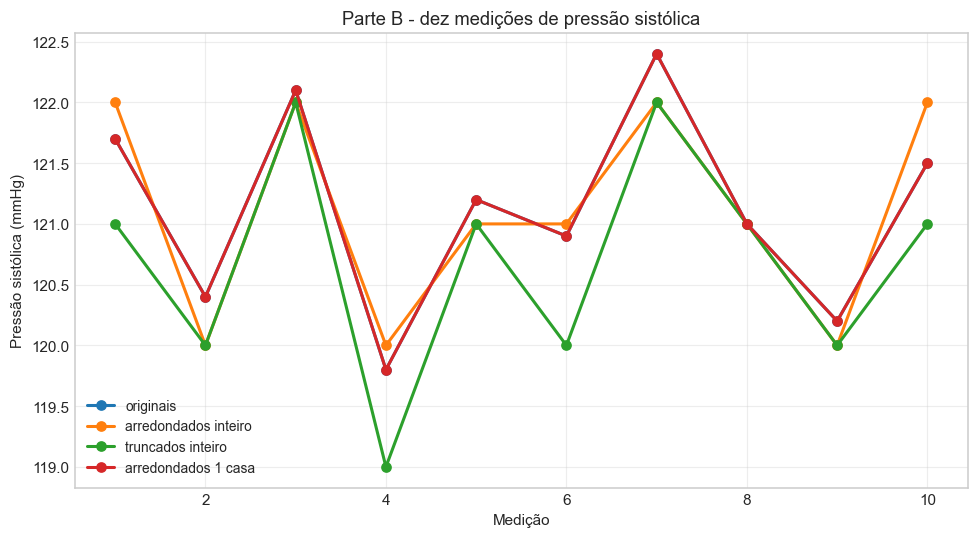

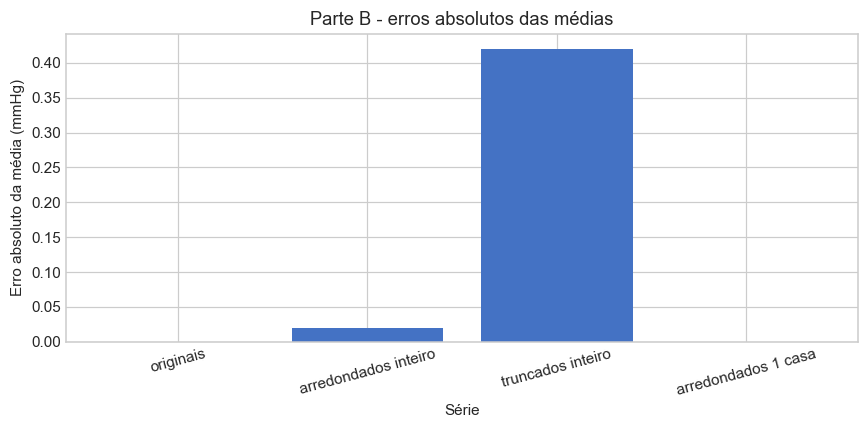

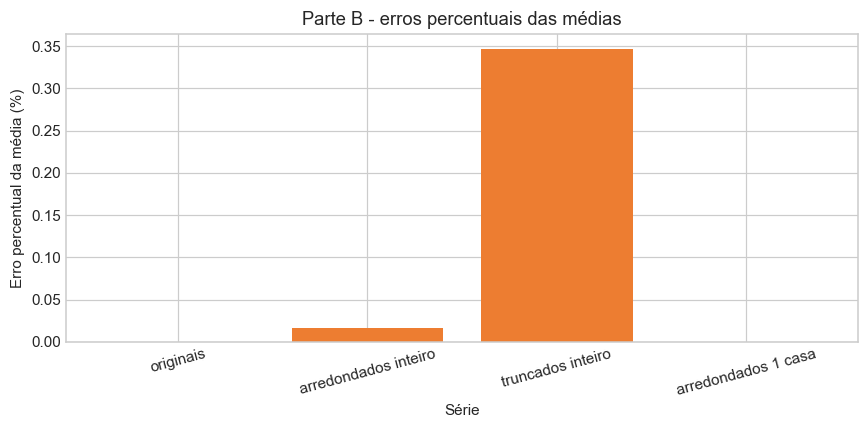

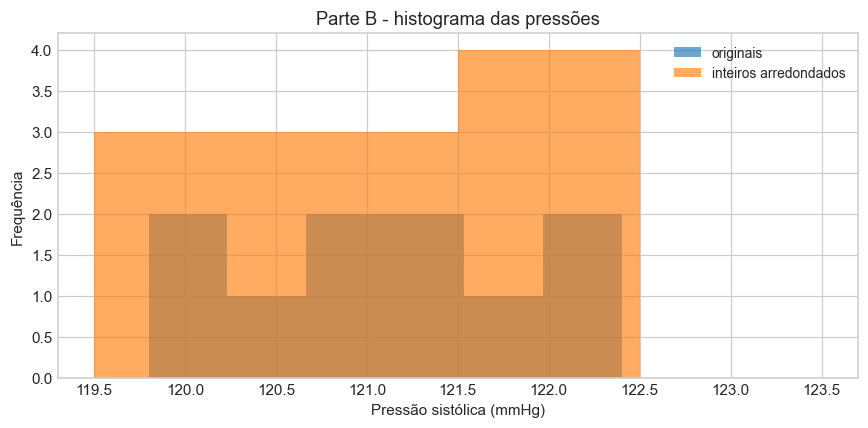

In [6]:
indices = np.arange(1, len(pressao_original) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
for nome, serie in series_pressao.items():
    ax.plot(indices, serie, marker="o", linewidth=2, label=nome)
ax.set_title("Parte B - dez medições de pressão sistólica")
ax.set_xlabel("Medição")
ax.set_ylabel("Pressão sistólica (mmHg)")
ax.legend()
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    tabela_pressao_erros["série"],
    tabela_pressao_erros["$E_a$ da média (mmHg)"],
    color="#4472c4",
)
ax.set_title("Parte B - erros absolutos das médias")
ax.set_xlabel("Série")
ax.set_ylabel("Erro absoluto da média (mmHg)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    tabela_pressao_erros["série"],
    tabela_pressao_erros["$E_{\\%}$ da média"],
    color="#ed7d31",
)
ax.set_title("Parte B - erros percentuais das médias")
ax.set_xlabel("Série")
ax.set_ylabel("Erro percentual da média (%)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pressao_original, bins=6, alpha=0.65, label="originais")
ax.hist(
    series_pressao["arredondados inteiro"],
    bins=np.arange(119.5, 123.6, 1),
    alpha=0.65,
    label="inteiros arredondados",
)
ax.set_title("Parte B - histograma das pressões")
ax.set_xlabel("Pressão sistólica (mmHg)")
ax.set_ylabel("Frequência")
ax.legend()
plt.tight_layout()
plt.show()

**Resposta - Parte B.** A representação inteira preserva razoavelmente a média desta pequena amostra, pois os erros percentuais das médias são baixos. Entretanto, reduz a informação decimal e altera a distribuição, a amplitude e o desvio-padrão. Assim, pode ser suficiente para uma visão aproximada da média, mas não preserva toda a variabilidade dos dados. Esta é uma análise numérica, sem interpretação médica.

## 5. Parte C - vazão em tubo de pequeno diâmetro

In [7]:
r_mm_c = 0.80
comprimento_m_c = 0.20
viscosidade_pa_s_c = 3.5e-3
delta_p_pa_c = 1200

r_m_c = r_mm_c * 1e-3
q_referencia_c = vazao_hagen_poiseuille(
    r_m_c,
    comprimento_m_c,
    viscosidade_pa_s_c,
    delta_p_pa_c,
)
cenarios_c = []


def adicionar_cenario(nome, raio_mm, viscosidade_pa_s, delta_p_pa):
    """Calcula um cenário da Parte C e adiciona seus erros à tabela."""
    vazao = vazao_hagen_poiseuille(
        raio_mm * 1e-3,
        comprimento_m_c,
        viscosidade_pa_s,
        delta_p_pa,
    )
    erro_absoluto, erro_relativo, erro_percentual = calcular_erros(
        q_referencia_c,
        vazao,
    )
    cenarios_c.append({
        "cenário": nome,
        "r usado (mm)": raio_mm,
        "mu usado (Pa s)": viscosidade_pa_s,
        "Delta p usado (Pa)": delta_p_pa,
        "Q (m³/s)": vazao,
        "Q (uL/s)": vazao * 1e9,
        "$E_a$ de Q (m³/s)": erro_absoluto,
        "$E_r$ de Q": erro_relativo,
        "$E_{\\%}$ de Q": erro_percentual,
    })

adicionar_cenario(
    "referência - valores fornecidos",
    r_mm_c,
    viscosidade_pa_s_c,
    delta_p_pa_c,
)
adicionar_cenario(
    "r arredondado para 1 casa",
    round(r_mm_c, 1),
    viscosidade_pa_s_c,
    delta_p_pa_c,
)
adicionar_cenario(
    "r truncado para 1 casa",
    truncar(r_mm_c, 1),
    viscosidade_pa_s_c,
    delta_p_pa_c,
)
adicionar_cenario(
    "mu arredondada para 3 casas",
    r_mm_c,
    round(viscosidade_pa_s_c, 3),
    delta_p_pa_c,
)
adicionar_cenario(
    "mu truncada para 3 casas",
    r_mm_c,
    truncar(viscosidade_pa_s_c, 3),
    delta_p_pa_c,
)
adicionar_cenario(
    "Delta p arredondada para centenas",
    r_mm_c,
    viscosidade_pa_s_c,
    round(delta_p_pa_c / 100) * 100,
)
adicionar_cenario(
    "Delta p truncada para centenas",
    r_mm_c,
    viscosidade_pa_s_c,
    truncar(delta_p_pa_c / 100, 0) * 100,
)
adicionar_cenario(
    "todas arredondadas simultaneamente",
    round(r_mm_c, 1),
    round(viscosidade_pa_s_c, 3),
    round(delta_p_pa_c / 100) * 100,
)
adicionar_cenario(
    "todas truncadas simultaneamente",
    truncar(r_mm_c, 1),
    truncar(viscosidade_pa_s_c, 3),
    truncar(delta_p_pa_c / 100, 0) * 100,
)

tabela_c = pd.DataFrame(cenarios_c)
mostrar_tabela(tabela_c, "Parte C - cenários da vazão")
print(
    f"Vazão de referência: {q_referencia_c:.6e} m³/s "
    f"= {q_referencia_c * 1e9:.6f} uL/s"
)

cenário,r usado (mm),mu usado (Pa s),Delta p usado (Pa),Q (m³/s),Q (uL/s),$E_a$ de Q (m³/s),$E_r$ de Q,$E_{\%}$ de Q
referência - valores fornecidos,0.800000,0.003500,1200.000000,0.000000,275.742075,0.000000,0.000000,0.000000
r arredondado para 1 casa,0.800000,0.003500,1200.000000,0.000000,275.742075,0.000000,0.000000,0.000000
r truncado para 1 casa,0.800000,0.003500,1200.000000,0.000000,275.742075,0.000000,0.000000,0.000000
mu arredondada para 3 casas,0.800000,0.004000,1200.000000,0.000000,241.274316,0.000000,0.125000,12.500000
mu truncada para 3 casas,0.800000,0.003000,1200.000000,0.000000,321.699088,0.000000,0.166667,16.666667
Delta p arredondada para centenas,0.800000,0.003500,1200.000000,0.000000,275.742075,0.000000,0.000000,0.000000
Delta p truncada para centenas,0.800000,0.003500,1200.000000,0.000000,275.742075,0.000000,0.000000,0.000000
todas arredondadas simultaneamente,0.800000,0.004000,1200.000000,0.000000,241.274316,0.000000,0.125000,12.500000
todas truncadas simultaneamente,0.800000,0.003000,1200.000000,0.000000,321.699088,0.000000,0.166667,16.666667


Vazão de referência: 2.757421e-07 m³/s = 275.742075 uL/s


**Resposta - Parte C.** Neste conjunto, arredondar ou truncar o raio $0{,}80$ mm para uma casa decimal mantém $0{,}8$ mm, portanto não altera $Q$. O mesmo acontece com $\Delta p=1200$ Pa ao aproximá-lo para centenas. A maior diferença aparece na viscosidade: arredondar $3{,}5	imes10^{-3}$ Pa s para três casas produz $0{,}004$ Pa s, enquanto truncar produz $0{,}003$ Pa s. Como $Q$ é inversamente proporcional a $\mu$, essa mudança afeta diretamente a vazão.

### C.2 Sensibilidade ao raio

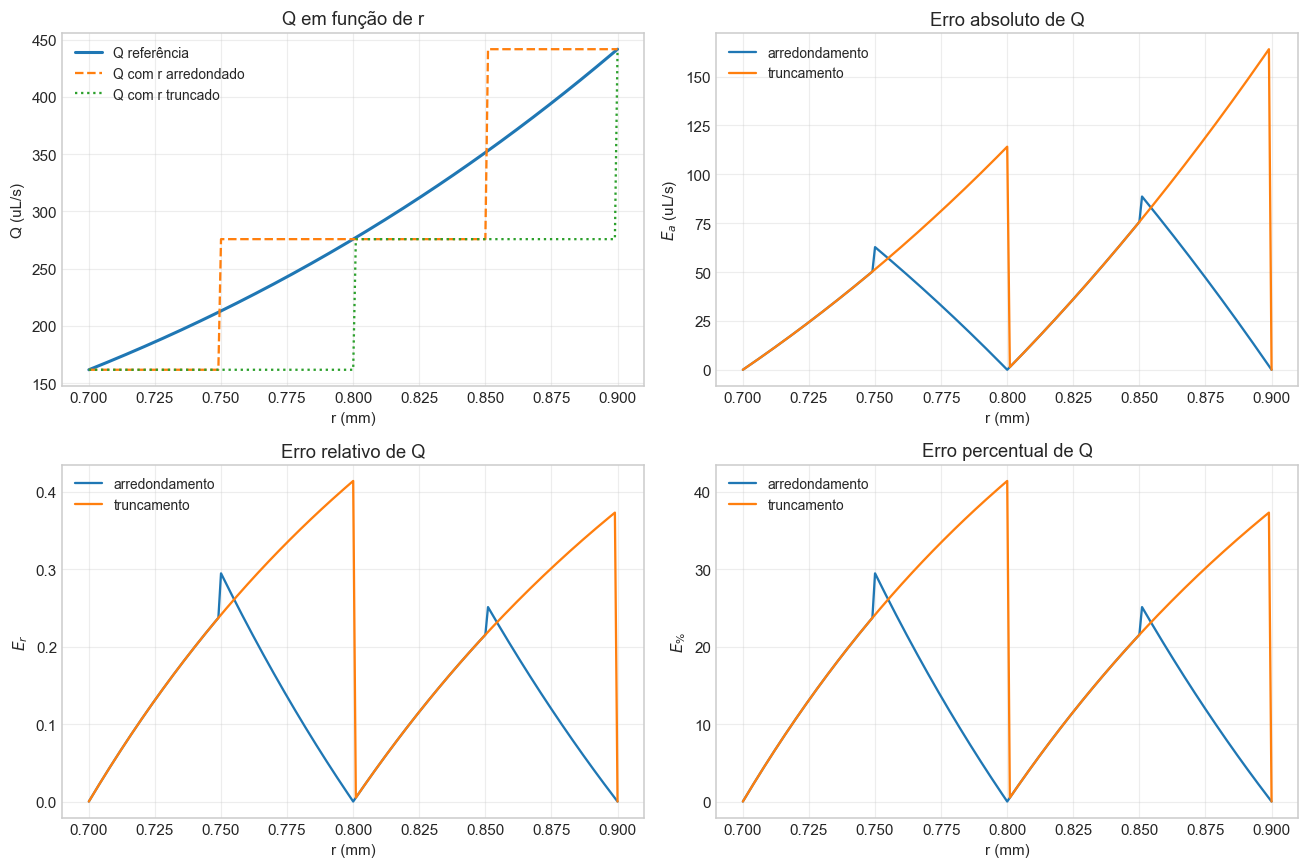

In [8]:
raios_mm = np.linspace(0.70, 0.90, 201)
q_referencia_raios = np.array([
    vazao_hagen_poiseuille(
        raio_mm * 1e-3,
        comprimento_m_c,
        viscosidade_pa_s_c,
        delta_p_pa_c,
    )
    for raio_mm in raios_mm
])
q_arredondado_raios = np.array([
    vazao_hagen_poiseuille(
        round(raio_mm, 1) * 1e-3,
        comprimento_m_c,
        viscosidade_pa_s_c,
        delta_p_pa_c,
    )
    for raio_mm in raios_mm
])
q_truncado_raios = np.array([
    vazao_hagen_poiseuille(
        truncar(raio_mm, 1) * 1e-3,
        comprimento_m_c,
        viscosidade_pa_s_c,
        delta_p_pa_c,
    )
    for raio_mm in raios_mm
])

ea_arredondado = np.abs(q_referencia_raios - q_arredondado_raios)
ea_truncado = np.abs(q_referencia_raios - q_truncado_raios)
er_arredondado = ea_arredondado / np.abs(q_referencia_raios)
er_truncado = ea_truncado / np.abs(q_referencia_raios)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

axes[0].plot(raios_mm, q_referencia_raios * 1e9, label="Q referência", linewidth=2)
axes[0].plot(
    raios_mm,
    q_arredondado_raios * 1e9,
    label="Q com r arredondado",
    linestyle="--",
)
axes[0].plot(
    raios_mm,
    q_truncado_raios * 1e9,
    label="Q com r truncado",
    linestyle=":",
)
axes[0].set_title("Q em função de r")
axes[0].set_xlabel("r (mm)")
axes[0].set_ylabel("Q (uL/s)")
axes[0].legend()

axes[1].plot(raios_mm, ea_arredondado * 1e9, label="arredondamento")
axes[1].plot(raios_mm, ea_truncado * 1e9, label="truncamento")
axes[1].set_title("Erro absoluto de Q")
axes[1].set_xlabel("r (mm)")
axes[1].set_ylabel("$E_a$ (uL/s)")
axes[1].legend()

axes[2].plot(raios_mm, er_arredondado, label="arredondamento")
axes[2].plot(raios_mm, er_truncado, label="truncamento")
axes[2].set_title("Erro relativo de Q")
axes[2].set_xlabel("r (mm)")
axes[2].set_ylabel("$E_r$")
axes[2].legend()

axes[3].plot(raios_mm, 100 * er_arredondado, label="arredondamento")
axes[3].plot(raios_mm, 100 * er_truncado, label="truncamento")
axes[3].set_title("Erro percentual de Q")
axes[3].set_xlabel("r (mm)")
axes[3].set_ylabel("$E_{\\%}$")
axes[3].legend()

for eixo in axes:
    eixo.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

**Resposta - Parte C.2.** O erro no raio é amplificado porque a vazão é proporcional a $r^4$. Pela aproximação linear, $\Delta Q/Q \approx 4\Delta r/r$. Portanto, um erro relativo pequeno no raio gera um erro relativo aproximadamente quatro vezes maior na vazão, além de possíveis assimetrias quando o cálculo é feito com $r+\Delta r$ ou $r-\Delta r$.

## 6. Parte D - escoamento em nanocateter

In [9]:
r_nm_d = 50.0
comprimento_um_d = 10.0
viscosidade_pa_s_d = 3.5e-3
delta_p_pa_d = 5000.0

r_m_d = r_nm_d * 1e-9
comprimento_m_d = comprimento_um_d * 1e-6
q_referencia_d = vazao_hagen_poiseuille(
    r_m_d,
    comprimento_m_d,
    viscosidade_pa_s_d,
    delta_p_pa_d,
)

print(f"Q(r = 50 nm): {q_referencia_d:.6e} m³/s")
print(f"Q(r = 50 nm): {q_referencia_d * 1e18:.6f} aL/s")

Q(r = 50 nm): 3.506242e-19 m³/s
Q(r = 50 nm): 0.350624 aL/s


### D.1 Erro geométrico

In [10]:
delta_r_nm_values = np.arange(0.1, 5.0 + 0.1, 0.1)
linhas_d1 = []

for delta_r_nm in delta_r_nm_values:
    raio_m_menor = (r_nm_d - delta_r_nm) * 1e-9
    raio_m_maior = (r_nm_d + delta_r_nm) * 1e-9
    q_menor = vazao_hagen_poiseuille(
        raio_m_menor,
        comprimento_m_d,
        viscosidade_pa_s_d,
        delta_p_pa_d,
    )
    q_maior = vazao_hagen_poiseuille(
        raio_m_maior,
        comprimento_m_d,
        viscosidade_pa_s_d,
        delta_p_pa_d,
    )
    erro_maximo_absoluto = max(
        abs(q_referencia_d - q_menor),
        abs(q_maior - q_referencia_d),
    )
    erro_maximo_relativo = erro_maximo_absoluto / abs(q_referencia_d)

    linhas_d1.append({
        "Delta r (nm)": delta_r_nm,
        "r- (nm)": r_nm_d - delta_r_nm,
        "r+ (nm)": r_nm_d + delta_r_nm,
        "Q(r-) (m³/s)": q_menor,
        "Q(r) (m³/s)": q_referencia_d,
        "Q(r+) (m³/s)": q_maior,
        "Erro máximo absoluto (m³/s)": erro_maximo_absoluto,
        "Erro máximo relativo": erro_maximo_relativo,
        "Erro máximo percentual (%)": 100 * erro_maximo_relativo,
        "Aproximação linear (%)": 100 * 4 * delta_r_nm / r_nm_d,
    })

tabela_d1 = pd.DataFrame(linhas_d1)
amostra_d1 = pd.concat([tabela_d1.head(10), tabela_d1.tail(5)])
mostrar_tabela(amostra_d1, "Parte D.1 - amostra da tabela de erro geométrico")

Delta r (nm),r- (nm),r+ (nm),Q(r-) (m³/s),Q(r) (m³/s),Q(r+) (m³/s),Erro máximo absoluto (m³/s),Erro máximo relativo,Erro máximo percentual (%),Aproximação linear (%)
0.100000,49.900000,50.100000,0.000000,0.000000,0.000000,0.000000,0.008024,0.802403,0.800000
0.200000,49.800000,50.200000,0.000000,0.000000,0.000000,0.000000,0.016096,1.609626,1.600000
0.300000,49.700000,50.300000,0.000000,0.000000,0.000000,0.000000,0.024217,2.421687,2.400000
0.400000,49.600000,50.400000,0.000000,0.000000,0.000000,0.000000,0.032386,3.238605,3.200000
0.500000,49.500000,50.500000,0.000000,0.000000,0.000000,0.000000,0.040604,4.060401,4.000000
0.600000,49.400000,50.600000,0.000000,0.000000,0.000000,0.000000,0.048871,4.887093,4.800000
0.700000,49.300000,50.700000,0.000000,0.000000,0.000000,0.000000,0.057187,5.718701,5.600000
0.800000,49.200000,50.800000,0.000000,0.000000,0.000000,0.000000,0.065552,6.555245,6.400000
0.900000,49.100000,50.900000,0.000000,0.000000,0.000000,0.000000,0.073967,7.396743,7.200000
1.000000,49.000000,51.000000,0.000000,0.000000,0.000000,0.000000,0.082432,8.243216,8.000000


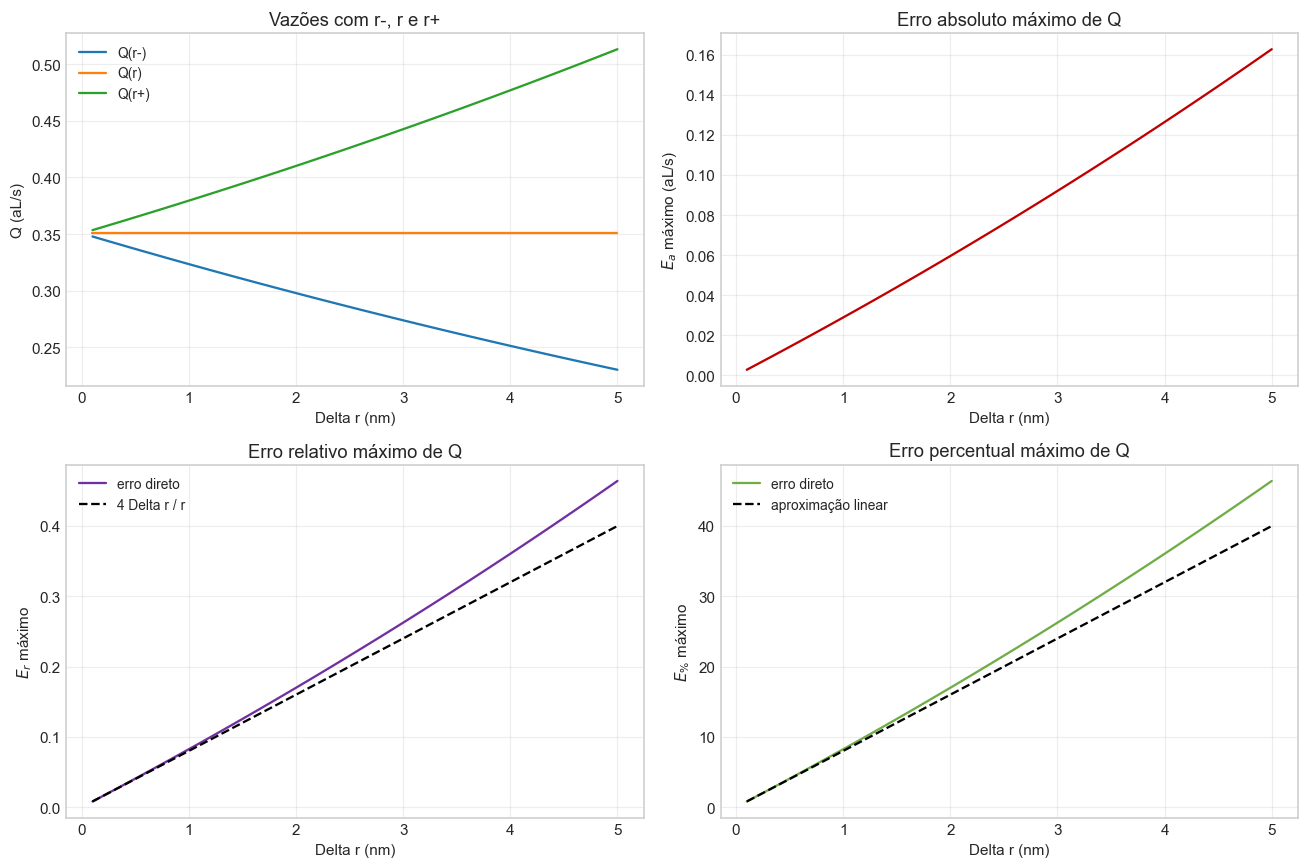

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

axes[0].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Q(r-) (m³/s)"] * 1e18,
    label="Q(r-)",
)
axes[0].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Q(r) (m³/s)"] * 1e18,
    label="Q(r)",
)
axes[0].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Q(r+) (m³/s)"] * 1e18,
    label="Q(r+)",
)
axes[0].set_title("Vazões com r-, r e r+")
axes[0].set_xlabel("Delta r (nm)")
axes[0].set_ylabel("Q (aL/s)")
axes[0].legend()

axes[1].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Erro máximo absoluto (m³/s)"] * 1e18,
    color="#c00000",
)
axes[1].set_title("Erro absoluto máximo de Q")
axes[1].set_xlabel("Delta r (nm)")
axes[1].set_ylabel("$E_a$ máximo (aL/s)")

axes[2].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Erro máximo relativo"],
    color="#7030a0",
    label="erro direto",
)
axes[2].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Aproximação linear (%)"] / 100,
    color="black",
    linestyle="--",
    label="4 Delta r / r",
)
axes[2].set_title("Erro relativo máximo de Q")
axes[2].set_xlabel("Delta r (nm)")
axes[2].set_ylabel("$E_r$ máximo")
axes[2].legend()

axes[3].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Erro máximo percentual (%)"],
    color="#70ad47",
    label="erro direto",
)
axes[3].plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Aproximação linear (%)"],
    color="black",
    linestyle="--",
    label="aproximação linear",
)
axes[3].set_title("Erro percentual máximo de Q")
axes[3].set_xlabel("Delta r (nm)")
axes[3].set_ylabel("$E_{\\%}$ máximo")
axes[3].legend()

for eixo in axes:
    eixo.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

A aproximação linear $\Delta Q/Q \approx 4\Delta r/r$ acompanha bem o erro direto para pequenas variações do raio. À medida que $\Delta r$ cresce, a diferença aumenta porque o cálculo exato contém termos de ordem superior associados à quarta potência. O aumento de vazão para $r+\Delta r$ também é maior que a redução para $r-\Delta r$, pois $r^4$ é uma função não linear.

### D.2 Precisão computacional

In [12]:
def vazao_numpy(raio_m, comprimento_m, viscosidade_pa_s, delta_p_pa, dtype):
    """Calcula r^4 e Q usando o tipo numérico especificado."""
    raio = dtype(raio_m)
    comprimento = dtype(comprimento_m)
    viscosidade = dtype(viscosidade_pa_s)
    delta_p = dtype(delta_p_pa)
    pi = dtype(np.pi)

    raio_quarta = raio**dtype(4)
    vazao = pi * raio_quarta * delta_p / (
        dtype(8) * viscosidade * comprimento
    )
    return raio_quarta, vazao


raio_quarta_32, q_32 = vazao_numpy(
    r_m_d,
    comprimento_m_d,
    viscosidade_pa_s_d,
    delta_p_pa_d,
    np.float32,
)
raio_quarta_64, q_64 = vazao_numpy(
    r_m_d,
    comprimento_m_d,
    viscosidade_pa_s_d,
    delta_p_pa_d,
    np.float64,
)

tabela_float = pd.DataFrame({
    "tipo": ["float32", "float64"],
    "r^4": [float(raio_quarta_32), float(raio_quarta_64)],
    "Q (m³/s)": [float(q_32), float(q_64)],
    "epsilon de máquina": [
        np.finfo(np.float32).eps,
        np.finfo(np.float64).eps,
    ],
})

diferenca_absoluta_float = abs(float(q_64) - float(q_32))
diferenca_relativa_float = diferenca_absoluta_float / abs(float(q_64))

mostrar_tabela(tabela_float, "Parte D.2 - representação numérica")
print(
    f"Diferença absoluta entre Q(float64) e Q(float32): "
    f"{diferenca_absoluta_float:.6e} m³/s"
)
print(
    f"Diferença relativa entre Q(float64) e Q(float32): "
    f"{diferenca_relativa_float:.6e}"
)

tipo,r^4,Q (m³/s),epsilon de máquina
float32,0.000000,0.000000,0.000000
float64,0.000000,0.000000,0.000000


Diferença absoluta entre Q(float64) e Q(float32): 5.228628e-26 m³/s
Diferença relativa entre Q(float64) e Q(float32): 1.491234e-07


In [13]:
razoes = np.array([10.0**(-expoente) for expoente in range(1, 15)])
linhas_cancelamento = []

for razao_relativa in razoes:
    delta_r = razao_relativa * r_m_d
    q_base = vazao_hagen_poiseuille(
        r_m_d,
        comprimento_m_d,
        viscosidade_pa_s_d,
        delta_p_pa_d,
    )
    q_variada = vazao_hagen_poiseuille(
        r_m_d + delta_r,
        comprimento_m_d,
        viscosidade_pa_s_d,
        delta_p_pa_d,
    )
    delta_1 = (q_variada - q_base) / q_base
    delta_2 = (1 + delta_r / r_m_d)**4 - 1
    diferenca = abs(delta_1 - delta_2)

    linhas_cancelamento.append({
        "Delta r / r": razao_relativa,
        "delta1 via subtração de Q": delta_1,
        "delta2 fórmula adimensional": delta_2,
        "diferença absoluta": diferenca,
        "diferença relativa": (
            diferenca / abs(delta_2) if delta_2 != 0 else np.nan
        ),
    })

tabela_cancelamento = pd.DataFrame(linhas_cancelamento)
mostrar_tabela(tabela_cancelamento, "Parte D.2 - teste de cancelamento numérico")

Delta r / r,delta1 via subtração de Q,delta2 fórmula adimensional,diferença absoluta,diferença relativa
0.100000,0.464100,0.464100,0.000000,0.000000
0.010000,0.040604,0.040604,0.000000,0.000000
0.001000,0.004006,0.004006,0.000000,0.000000
0.000100,0.000400,0.000400,0.000000,0.000000
0.000010,0.000040,0.000040,0.000000,0.000000
0.000001,0.000004,0.000004,0.000000,0.000000
0.000000,0.000000,0.000000,0.000000,0.000000
0.000000,0.000000,0.000000,0.000000,0.000000
0.000000,0.000000,0.000000,0.000000,0.000000
0.000000,0.000000,0.000000,0.000000,0.000001


Para `float32`, a precisão de máquina é menor que para `float64`, embora ambas as representações produzam valores de $Q$ muito próximos neste exemplo. Já a expressão $\delta_1=[Q(r+\Delta r)-Q(r)]/Q(r)$ pode sofrer perda de significância quando $\Delta r/r$ é muito pequeno, pois subtrai duas vazões quase iguais. A forma adimensional $\delta_2=(1+\Delta r/r)^4-1$ reduz esse efeito.

### D.3 Fenômeno físico

Em escala nanométrica, a redução do tamanho do canal aumenta a razão superfície/volume. Com isso, os efeitos viscosos e as interações próximas à parede passam a ter maior influência no escoamento. O modelo de Hagen-Poiseuille é útil como aproximação didática, mas assume fluido contínuo, escoamento laminar plenamente desenvolvido, tubo cilíndrico rígido e condições simples na parede. Portanto, um resultado com muitas casas decimais pode ser aritmeticamente preciso e, ainda assim, fisicamente inadequado se o modelo não representar os fenômenos dominantes na escala analisada.

## 7. Parte E - quadro único de resultados em PNG

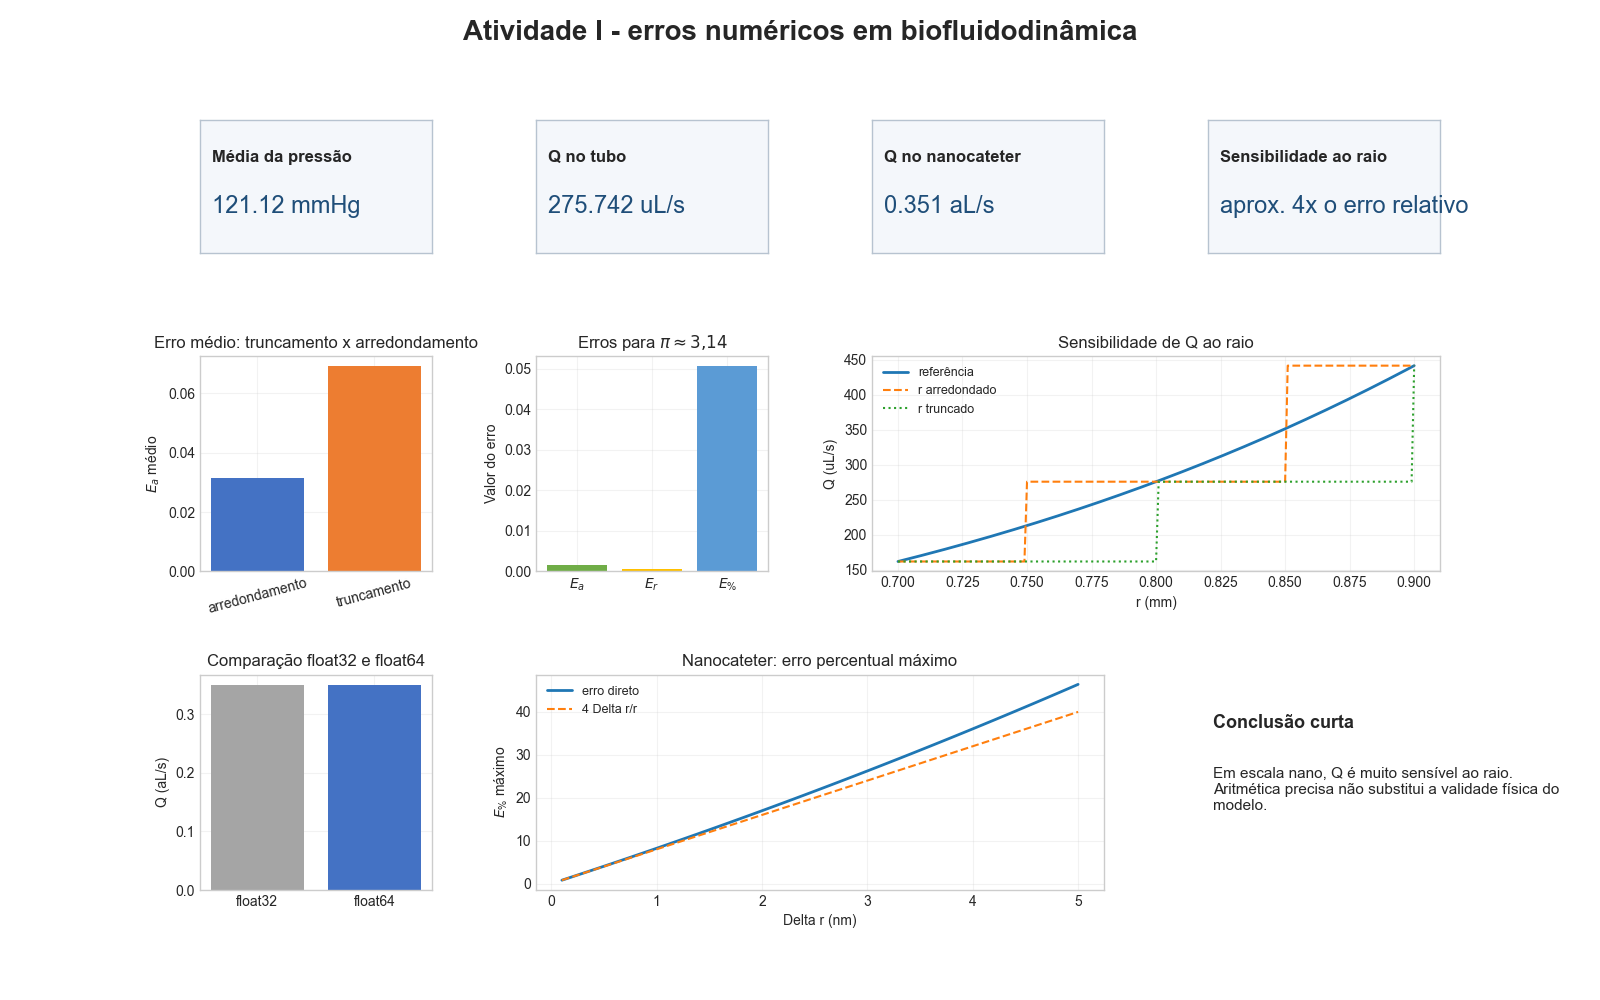

In [14]:
fig = plt.figure(figsize=(16, 10), dpi=100)
grid = fig.add_gridspec(
    3,
    4,
    height_ratios=[0.8, 1.3, 1.3],
    hspace=0.55,
    wspace=0.45,
)
fig.suptitle(
    "Atividade I - erros numéricos em biofluidodinâmica",
    fontsize=20,
    fontweight="bold",
)

card_data = [
    ("Média da pressão", f"{media_referencia_pressao:.2f} mmHg"),
    ("Q no tubo", f"{q_referencia_c * 1e9:.3f} uL/s"),
    ("Q no nanocateter", f"{q_referencia_d * 1e18:.3f} aL/s"),
    ("Sensibilidade ao raio", "aprox. 4x o erro relativo"),
]

for indice, (titulo, valor) in enumerate(card_data):
    eixo = fig.add_subplot(grid[0, indice])
    eixo.set_facecolor("#f4f7fb")
    for spine in eixo.spines.values():
        spine.set_visible(True)
        spine.set_color("#b7c3d0")
    eixo.set_xticks([])
    eixo.set_yticks([])
    eixo.text(
        0.05,
        0.68,
        titulo,
        fontsize=12,
        fontweight="bold",
        transform=eixo.transAxes,
    )
    eixo.text(
        0.05,
        0.30,
        valor,
        fontsize=17,
        color="#1f4e79",
        transform=eixo.transAxes,
    )

ax = fig.add_subplot(grid[1, 0])
resumo_a = tabela_a.groupby("método")["$E_a$"].mean().reset_index()
ax.bar(resumo_a["método"], resumo_a["$E_a$"], color=["#4472c4", "#ed7d31"])
ax.set_title("Erro médio: truncamento x arredondamento")
ax.set_ylabel("$E_a$ médio")
ax.tick_params(axis="x", rotation=15)

ax = fig.add_subplot(grid[1, 1])
erros_pi = pd.DataFrame([
    {"tipo": "$E_a$", "valor": calcular_erros(math.pi, 3.14)[0]},
    {"tipo": "$E_r$", "valor": calcular_erros(math.pi, 3.14)[1]},
    {"tipo": "$E_{\\%}$", "valor": calcular_erros(math.pi, 3.14)[2]},
])
ax.bar(erros_pi["tipo"], erros_pi["valor"], color=["#70ad47", "#ffc000", "#5b9bd5"])
ax.set_title("Erros para $\\pi \\approx 3{,}14$")
ax.set_ylabel("Valor do erro")

ax = fig.add_subplot(grid[1, 2:])
ax.plot(raios_mm, q_referencia_raios * 1e9, linewidth=2, label="referência")
ax.plot(raios_mm, q_arredondado_raios * 1e9, linestyle="--", label="r arredondado")
ax.plot(raios_mm, q_truncado_raios * 1e9, linestyle=":", label="r truncado")
ax.set_title("Sensibilidade de Q ao raio")
ax.set_xlabel("r (mm)")
ax.set_ylabel("Q (uL/s)")
ax.legend()

ax = fig.add_subplot(grid[2, 0])
ax.bar(
    tabela_float["tipo"],
    tabela_float["Q (m³/s)"] * 1e18,
    color=["#a5a5a5", "#4472c4"],
)
ax.set_title("Comparação float32 e float64")
ax.set_ylabel("Q (aL/s)")

ax = fig.add_subplot(grid[2, 1:3])
ax.plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Erro máximo percentual (%)"],
    label="erro direto",
    linewidth=2,
)
ax.plot(
    tabela_d1["Delta r (nm)"],
    tabela_d1["Aproximação linear (%)"],
    linestyle="--",
    label="4 Delta r/r",
)
ax.set_title("Nanocateter: erro percentual máximo")
ax.set_xlabel("Delta r (nm)")
ax.set_ylabel("$E_{\\%}$ máximo")
ax.legend()

ax = fig.add_subplot(grid[2, 3])
ax.axis("off")
ax.text(0.02, 0.75, "Conclusão curta", fontsize=13, fontweight="bold")
ax.text(
    0.02,
    0.38,
    "Em escala nano, Q é muito sensível ao raio.\n"
    "Aritmética precisa não substitui a validade física do modelo.",
    fontsize=11,
    wrap=True,
)

for eixo in fig.axes:
    eixo.grid(True, alpha=0.25)

png_path = output_dir / "quadro_unico_resultados.png"
fig.savefig(png_path, dpi=100)
plt.close(fig)
display(IPythonImage(filename=str(png_path)))

## 8. GIF demonstrativo

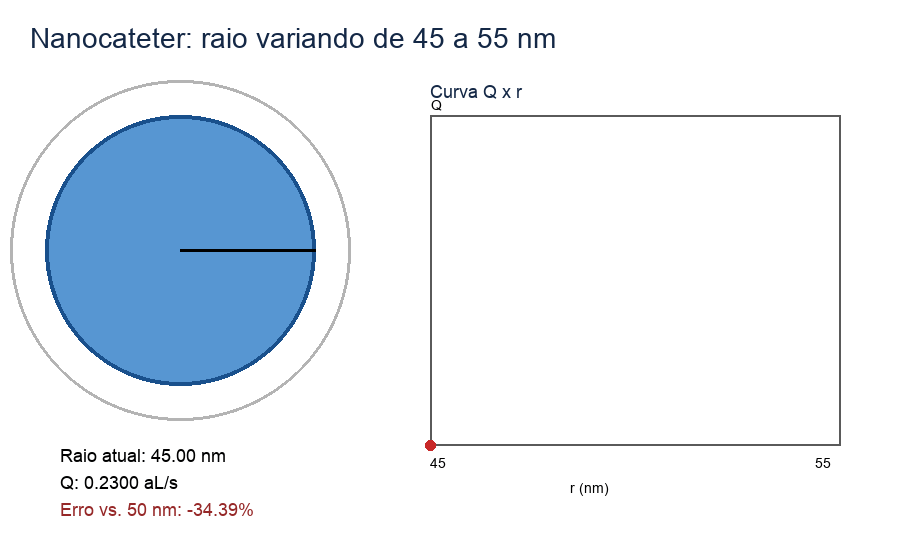

In [15]:
def criar_frame_gif(frame_index, total_frames, largura=900, altura=560):
    """Cria um quadro da animação com seção do canal e curva Q x r."""
    raio_nm = 45 + 10 * frame_index / (total_frames - 1)
    raio_m = raio_nm * 1e-9
    q_atual = vazao_hagen_poiseuille(
        raio_m,
        comprimento_m_d,
        viscosidade_pa_s_d,
        delta_p_pa_d,
    )
    erro_percentual = 100 * (q_atual - q_referencia_d) / q_referencia_d

    imagem = Image.new("RGB", (largura, altura), "white")
    desenho = ImageDraw.Draw(imagem)

    try:
        fonte_titulo = ImageFont.truetype("Arial.ttf", 28)
        fonte = ImageFont.truetype("Arial.ttf", 18)
        fonte_pequena = ImageFont.truetype("Arial.ttf", 14)
    except OSError:
        fonte_titulo = fonte = fonte_pequena = None

    desenho.text(
        (30, 22),
        "Nanocateter: raio variando de 45 a 55 nm",
        fill=(20, 40, 70),
        font=fonte_titulo,
    )

    # Seção transversal do canal.
    centro = (180, 250)
    escala = 3.0
    raio_pixels = int(raio_nm * escala)
    desenho.ellipse(
        (
            centro[0] - 170,
            centro[1] - 170,
            centro[0] + 170,
            centro[1] + 170,
        ),
        outline=(180, 180, 180),
        width=3,
    )
    desenho.ellipse(
        (
            centro[0] - raio_pixels,
            centro[1] - raio_pixels,
            centro[0] + raio_pixels,
            centro[1] + raio_pixels,
        ),
        fill=(87, 150, 210),
        outline=(25, 80, 140),
        width=4,
    )
    desenho.line(
        (centro[0], centro[1], centro[0] + raio_pixels, centro[1]),
        fill=(0, 0, 0),
        width=3,
    )
    desenho.text(
        (60, 445),
        f"Raio atual: {raio_nm:.2f} nm",
        fill=(0, 0, 0),
        font=fonte,
    )
    desenho.text(
        (60, 472),
        f"Q: {q_atual * 1e18:.4f} aL/s",
        fill=(0, 0, 0),
        font=fonte,
    )
    desenho.text(
        (60, 499),
        f"Erro vs. 50 nm: {erro_percentual:+.2f}%",
        fill=(150, 40, 40),
        font=fonte,
    )

    # Curva Q x r construída progressivamente.
    plot_x0, plot_y0 = 430, 115
    plot_width, plot_height = 410, 330
    desenho.rectangle(
        (
            plot_x0,
            plot_y0,
            plot_x0 + plot_width,
            plot_y0 + plot_height,
        ),
        outline=(90, 90, 90),
        width=2,
    )
    desenho.text(
        (plot_x0, plot_y0 - 34),
        "Curva Q x r",
        fill=(20, 40, 70),
        font=fonte,
    )
    desenho.text(
        (plot_x0 + 140, plot_y0 + plot_height + 35),
        "r (nm)",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )
    desenho.text(
        (plot_x0 + 1, plot_y0 - 18),
        "Q",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )

    raios_curva = np.linspace(45, raio_nm, frame_index + 1)
    q_curva = np.array([
        vazao_hagen_poiseuille(
            raio * 1e-9,
            comprimento_m_d,
            viscosidade_pa_s_d,
            delta_p_pa_d,
        )
        for raio in raios_curva
    ]) * 1e18
    raios_totais = np.linspace(45, 55, 200)
    q_total = np.array([
        vazao_hagen_poiseuille(
            raio * 1e-9,
            comprimento_m_d,
            viscosidade_pa_s_d,
            delta_p_pa_d,
        )
        for raio in raios_totais
    ]) * 1e18
    q_minimo, q_maximo = q_total.min(), q_total.max()

    pontos = []
    for raio, vazao in zip(raios_curva, q_curva):
        px = plot_x0 + int((raio - 45) / 10 * plot_width)
        py = plot_y0 + plot_height - int(
            (vazao - q_minimo) / (q_maximo - q_minimo) * plot_height
        )
        pontos.append((px, py))

    if len(pontos) > 1:
        desenho.line(pontos, fill=(87, 150, 210), width=4)
    if pontos:
        px, py = pontos[-1]
        desenho.ellipse((px - 5, py - 5, px + 5, py + 5), fill=(200, 40, 40))

    desenho.text(
        (plot_x0, plot_y0 + plot_height + 10),
        "45",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )
    desenho.text(
        (plot_x0 + plot_width - 25, plot_y0 + plot_height + 10),
        "55",
        fill=(0, 0, 0),
        font=fonte_pequena,
    )
    return imagem


numero_de_quadros = 40
frames = [
    criar_frame_gif(indice, numero_de_quadros)
    for indice in range(numero_de_quadros)
]
gif_path = output_dir / "nanocateter_vazao_raio.gif"
frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=120,
    loop=0,
)
display(IPythonImage(filename=str(gif_path)))

## 9. Conclusão final

Os resultados mostram que a escolha entre truncamento e arredondamento afeta a qualidade da aproximação, sendo o arredondamento geralmente mais fiel por escolher o valor mais próximo. Nas medidas de pressão, os erros da média foram pequenos ao usar valores inteiros, mas a variabilidade foi modificada. Na relação de Hagen-Poiseuille, o raio é a variável mais sensível porque aparece elevado à quarta potência, amplificando pequenas incertezas geométricas. No nanocateter, a comparação entre `float32` e `float64` reforça que precisão computacional e validade física do modelo são conceitos diferentes. Assim, uma boa análise numérica deve considerar simultaneamente unidades, escala, propagação de incertezas e hipóteses físicas.